# AlagaAlerta: risco de alagamento por região de São Paulo

**GS 2026.2 CitizenTech · Inteligência Artificial & Machine Learning**

Integrantes: Renato Luiz Cordão (RM556403), Vitor Victorino Couto (RM554965), Victoria Moura (RM555474), Fabricio Bettarello (RM554638), Enzo Miletta (RM98677)

O AlagaAlerta tem três partes: um sensor ultrassônico no ESP32 que mede o nível da água em bueiros e córregos, um backend que gera alertas por bairro e um app em que o morador vê os pontos de risco e relata alagamentos. Este notebook cuida da parte de ML. A ideia é usar o histórico real de chuva e de alagamentos da cidade para dizer, num dia de chuva, em quais regiões a chance de alagar é alta.

**Pergunta de ML:** sabendo quanto choveu, e com que intensidade, nas estações do INMET em São Paulo, qual a probabilidade de o CGE registrar pelo menos um ponto de alagamento em cada região da cidade naquele dia?

Cada linha da tabela é um par (dia, região), e a resposta é "alagou" (1) ou "não alagou" (0). Ou seja, é um problema de **classificação binária**.

Roteiro do notebook:

1. Dados: INMET e CGE
2. Limpeza e montagem da tabela
3. Olhada nos dados
4. Divisão treino/teste
5. Modelo e busca de hiperparâmetros
6. Resultados em treino e teste
7. O que isso significa para o morador

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, GroupKFold, cross_val_predict
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

PASTA_DADOS = Path("dados")
PASTA_FIG = Path("figuras")
PASTA_FIG.mkdir(exist_ok=True)
SEMENTE = 42

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True})
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)

AZUL, LARANJA, CINZA = "#1f6fb4", "#e8772e", "#8c8c8c"

## 1. Dados

Usamos duas fontes públicas sobre a cidade de São Paulo, no período de **01/01/2019 a 31/12/2025**. Os links, as colunas e o passo a passo para baixar de novo estão em `dados/README.md`.

| Fonte | O que tem | Como foi obtido |
|---|---|---|
| **INMET**, estações automáticas A701 (Mirante de Santana, zona norte) e A771 (Interlagos, zona sul) | chuva, temperatura e umidade de hora em hora | `coleta/baixar_inmet.py`, que baixa os arquivos anuais do portal do INMET |
| **CGE**, Centro de Gerenciamento de Emergências Climáticas da Prefeitura | cada ponto de alagamento registrado, com dia, região, subprefeitura, horário, endereço e se ficou transitável ou não | `coleta/coletar_cge.py`, que lê a página de alagamentos do CGE dia por dia |

O recorte começa em 2019 porque a estação de Interlagos só começou a operar em março de 2018. Assim, todos os anos ficam completos com as duas estações dentro da capital.

### 1.1 INMET

Os CSVs do INMET têm 8 linhas de cabeçalho com dados da estação, separador `;`, vírgula como decimal e `-9999` quando o sensor não mediu. A hora vem em UTC.

In [2]:
# o nome da coluna muda um pouco de um ano pro outro
COLUNAS_INMET = {
    "PRECIPITA": "chuva",
    "TEMPERATURA DO AR": "temperatura",
    "UMIDADE RELATIVA DO AR, HORARIA": "umidade",
}


def ler_estacao(codigo):
    arquivos = sorted((PASTA_DADOS / "brutos" / "inmet").glob(f"*_{codigo}_*.CSV"))
    df = pd.concat([pd.read_csv(a, sep=";", skiprows=8, encoding="latin-1",
                                decimal=",", na_values=["-9999"]) for a in arquivos],
                   ignore_index=True)

    renomear = {col: novo for col in df.columns for trecho, novo in COLUNAS_INMET.items()
                if col.upper().startswith(trecho)}
    df["datahora"] = pd.to_datetime(df["Data"] + " " + df["Hora UTC"].str[:2],
                                    format="%Y/%m/%d %H", utc=True)
    df = df.rename(columns=renomear)[["datahora", *COLUNAS_INMET.values()]]
    df["estacao"] = codigo
    return df


horario = pd.concat([ler_estacao(c) for c in ["A701", "A771", "A755"]], ignore_index=True)
print(f"{len(horario):,} leituras horárias")
horario.head()

184,104 leituras horárias


,datahora,chuva,temperatura,umidade,estacao
0,2019-01-01 00:00:00+00:00,0.0,22.8,69.0,A701
1,2019-01-01 01:00:00+00:00,0.0,22.3,71.0,A701
2,2019-01-01 02:00:00+00:00,0.0,22.1,73.0,A701
3,2019-01-01 03:00:00+00:00,0.0,21.6,76.0,A701
4,2019-01-01 04:00:00+00:00,0.0,21.6,76.0,A701


Antes de decidir quais estações entram, vale ver quanto falta de chuva em cada uma, por ano (% das horas sem leitura):

In [3]:
falta = (horario.assign(ano=horario["datahora"].dt.year)
         .groupby(["estacao", "ano"])["chuva"]
         .agg(lambda s: s.isna().mean() * 100)
         .unstack("ano")
         .round(1))
falta

ano,2019,2020,2021,2022,2023,2024,2025
estacao,,,,,,,
A701,0.0,0.0,0.0,0.0,7.4,0.2,0.5
A755,19.5,41.8,95.3,6.6,17.7,89.0,59.1
A771,0.0,0.0,0.0,5.5,2.0,0.1,0.3


A estação de Barueri (A755) tem um problema sério: ficou sem medir chuva em 95% das horas de 2021, 89% de 2024 e 59% de 2025. Como 2024 e 2025 vão ser o conjunto de teste, usar essa estação faria o modelo depender de uma variável que praticamente some na hora da prova. Por isso ela sai. A701 e A771 ficam, com no máximo 7,4% de horas sem chuva medida em um ano (A701 em 2023).

In [4]:
horario = horario[horario["estacao"] != "A755"].copy()

print("chuva horária: mínimo", horario["chuva"].min(), "mm | máximo", horario["chuva"].max(), "mm")
horario.groupby("estacao")[["chuva", "temperatura", "umidade"]].describe().T

chuva horária: mínimo 0.0 mm | máximo 82.0 mm


estacao                 A701       A771
chuva       count  60652.000  60669.000
            mean       0.179      0.162
            std        1.434      1.248
            min        0.000      0.000
            25%        0.000      0.000
            50%        0.000      0.000
            75%        0.000      0.000
            max       82.000     56.000
temperatura count  61088.000  60177.000
            mean      20.685     19.610
            std        4.653      4.587
            min        4.400      3.700
            25%       17.400     16.400
            50%       20.400     19.300
            75%       23.600     22.200
            max       37.300     37.900
umidade     count  61087.000  59810.000
            mean      68.099     81.963
            std       17.622     17.618
            min       12.000      8.000
            25%       56.000     72.000
            50%       73.000     88.000
            75%       82.000     95.000
            max      100.000    100.000

Não há chuva negativa. O maior valor horário é 82 mm, no Mirante, em 24/01/2025 por volta das 16h. Parece exagero, mas confere com o CGE: nesse dia foram registrados 39 pontos de alagamento, 10 deles na zona norte, onde fica a estação. O valor fica. A temperatura (de 3,7 °C a 37,9 °C) também está dentro do normal para São Paulo.

Na umidade apareceu algo estranho. A média de Interlagos (82%) é bem maior que a do Mirante (68%), e o máximo de 100% aparece com frequência. Umidade de exatamente 100% por horas seguidas costuma ser sensor travado, então vale contar quantas horas ficaram assim:

In [5]:
travado = (horario.assign(ano=horario["datahora"].dt.year)
           .groupby(["estacao", "ano"])["umidade"]
           .agg(lambda s: (s == 100).mean() * 100)
           .unstack("ano")
           .round(1))
travado

ano,2019,2020,2021,2022,2023,2024,2025
estacao,,,,,,,
A701,0.0,0.0,0.0,0.0,0.0,0.2,0.1
A771,0.0,0.0,18.6,39.7,32.3,0.0,0.0


O sensor de umidade de Interlagos ficou travado em 100% em 18,6% das horas de 2021, 39,7% de 2022 e 32,3% de 2023, e voltou ao normal em 2024. Como o defeito aparece só nos anos de treino, o modelo aprenderia uma relação com um sensor quebrado que não vale no teste. A umidade da A771 sai. A chuva e a temperatura dessa estação continuam, porque não têm esse problema.

Agora a conversão de fuso. O CGE registra os alagamentos no horário de Brasília e o INMET mede em UTC (3 horas à frente). Se a chuva fosse somada por dia em UTC, a chuva das 21h às 23h59 cairia no dia seguinte, justo no horário em que muito temporal de verão acontece. Por isso convertemos tudo para `America/Sao_Paulo` antes de agrupar. O fuso também dá conta do horário de verão, que ainda valia nas primeiras semanas de 2019.

Para cada estação e cada dia, calculamos:

- `chuva_dia`: total do dia (mm)
- `chuva_max_1h`: a hora mais chuvosa do dia (mm)
- `chuva_max_3h`: o maior acumulado em 3 horas seguidas (mm), que pega o temporal que dura um pouco mais
- `temp_max` e `umidade_media`: dia quente e úmido costuma vir antes de pancada de verão

Se a estação ficou mais de 4 horas sem medir chuva no dia, as colunas de chuva desse dia ficam vazias. Um total com buraco subestimaria a chuva, e um zero falso é pior do que um valor faltando.

In [6]:
horario["datahora"] = (horario["datahora"].dt.tz_convert("America/Sao_Paulo")
                       .dt.tz_localize(None))


def resumo_diario(df):
    df = df.set_index("datahora").sort_index()
    # o fim do horario de verao (16/02/2019) repete a hora 23h
    df = df[~df.index.duplicated()].asfreq("h")

    chuva_3h = df["chuva"].rolling(3, min_periods=3).sum()
    dia = df.index.normalize()
    g = df.groupby(dia)
    out = pd.DataFrame({
        "chuva_dia": g["chuva"].sum(min_count=1),
        "chuva_max_1h": g["chuva"].max(),
        "chuva_max_3h": chuva_3h.groupby(dia).max(),
        "temp_max": g["temperatura"].max(),
        "umidade_media": g["umidade"].mean(),
    })
    horas_medidas = g["chuva"].count()
    out.loc[horas_medidas < 20, ["chuva_dia", "chuva_max_1h", "chuva_max_3h"]] = np.nan
    return out


partes = []
for codigo, df in horario.groupby("estacao"):
    d = resumo_diario(df.drop(columns="estacao"))
    d.columns = [f"{c}_{codigo}" for c in d.columns]
    partes.append(d)

clima = pd.concat(partes, axis=1).loc["2019-01-01":"2025-12-31"]
clima.index.name = "data"
clima = clima.drop(columns="umidade_media_A771")
print(clima.shape)
print("dias sem chuva_dia válida:", clima.filter(like="chuva_dia").isna().sum().to_dict())

(2557, 9)
dias sem chuva_dia válida: {'chuva_dia_A701': 37, 'chuva_dia_A771': 38}


Duas variáveis a mais, pensando em como alagamento funciona na prática:

- `chuva_maior_estacao`: o maior total do dia entre as duas estações. A chuva de verão em SP é muito localizada, e às vezes cai o mundo em Interlagos enquanto no Mirante só garoa.
- `chuva_ontem`, `chuva_3d_antes` e `chuva_7d_antes`: a chuva dos dias anteriores, que mede o quanto o solo e as galerias já estão cheios. Usamos a média das duas estações.

In [7]:
chuva_media = clima[["chuva_dia_A701", "chuva_dia_A771"]].mean(axis=1)

clima["chuva_maior_estacao"] = clima[["chuva_dia_A701", "chuva_dia_A771"]].max(axis=1)
clima["chuva_ontem"] = chuva_media.shift(1)
clima["chuva_3d_antes"] = chuva_media.shift(1).rolling(3, min_periods=2).sum()
clima["chuva_7d_antes"] = chuva_media.shift(1).rolling(7, min_periods=5).sum()
clima.describe().T[["count", "mean", "50%", "max"]]

,count,mean,50%,max
chuva_dia_A701,2520.0,4.292,0.000,142.400
chuva_max_1h_A701,2520.0,2.269,0.000,82.000
chuva_max_3h_A701,2520.0,3.453,0.000,123.800
temp_max_A701,2556.0,26.088,26.500,37.300
umidade_media_A701,2556.0,68.099,69.208,94.083
chuva_dia_A771,2519.0,3.898,0.200,103.200
chuva_max_1h_A771,2519.0,1.991,0.200,56.000
chuva_max_3h_A771,2519.0,3.051,0.200,86.000
temp_max_A771,2517.0,24.875,25.100,37.900
chuva_maior_estacao,2556.0,5.663,0.200,142.400


### 1.2 CGE

O script de coleta salvou um ponto de alagamento por linha e, num arquivo separado, todos os dias consultados. O segundo arquivo importa porque um dia que não aparece na lista de pontos pode ser um dia sem alagamento ou um dia que falhou no download. Com a lista de dias consultados dá para ter certeza de que é a primeira opção.

In [8]:
pontos = pd.read_csv(PASTA_DADOS / "brutos" / "cge_alagamentos.csv", parse_dates=["data"])
dias_cge = pd.read_csv(PASTA_DADOS / "brutos" / "cge_dias.csv", parse_dates=["data"])

print(f"{len(dias_cge)} dias consultados ({dias_cge['data'].min():%d/%m/%Y} a {dias_cge['data'].max():%d/%m/%Y})")
print(f"{len(pontos)} pontos de alagamento em {(dias_cge['n_pontos'] > 0).sum()} dias diferentes")
pontos.sample(5, random_state=1)

2557 dias consultados (01/01/2019 a 31/12/2025)
5647 pontos de alagamento em 597 dias diferentes


,data,regiao,subprefeitura,inicio,fim,local,sentido,referencia,situacao
987,2019-12-05,Zona Oeste,Lapa,16:29,17:04,AV. CANDIDO PORTINARI (JAGUARA),AMBOS - ÚNICA,R PAUVA,Inativo Intransitável
1676,2020-02-24,Zona Sudeste,Vila Mariana,18:11,19:49,AV. REPUBLICA DO LIBANO (MOEMA),IBIRAPUERA/JABAQUARA,AV ANTONIO J. DE MOURA ANDRADE,Inativo Transitável
1685,2020-02-25,Zona Leste,Mooca,18:28,18:45,AV. ALCÂNTARA MACHADO (BELEM),AMBOS,R WANDENKOLK,Inativo Transitável
5093,2025-01-22,Zona Leste,Itaquera,17:20,19:18,R VICTORIO SANTIM,CENTRO/BAIRRO,R ITALINA,Inativo Transitável
3573,2023-01-29,Zona Leste,São Mateus,17:35,21:36,AV ARICANDUVA,AMBOS,R MANILHA,Inativo Intransitável


In [9]:
repetidos = pontos.duplicated().sum()
pontos = pontos.drop_duplicates()
print("linhas repetidas removidas:", repetidos)
print("pontos sem região:", pontos["regiao"].isna().sum())

print()
print(pontos["regiao"].value_counts().to_string())
print()
print(pontos["situacao"].value_counts().to_string())

linhas repetidas removidas: 4
pontos sem região: 0

regiao
Zona Leste      1413
Zona Oeste      1310
Centro           968
Zona Norte       818
Zona Sul         700
Zona Sudeste     434

situacao
Inativo Transitável      3067
Inativo Intransitável    2568
Ativo Transitável           8


O CGE divide a cidade em 6 regiões. Cada uma vira uma linha por dia, e o alvo é 1 quando a região teve pelo menos um ponto de alagamento naquele dia.

Ficamos com a região e não com a subprefeitura (são 32) porque, por subprefeitura, quase todo dia é zero e o modelo teria pouquíssimo exemplo positivo para aprender. No app, o risco da região é refinado pelo sensor de cada bueiro e pelos relatos dos moradores.

In [10]:
REGIOES = sorted(pontos["regiao"].unique())
grade = pd.MultiIndex.from_product([dias_cge["data"], REGIOES], names=["data", "regiao"])

alvo = (pontos.groupby(["data", "regiao"]).size()
        .reindex(grade, fill_value=0)
        .rename("n_pontos")
        .reset_index())
alvo["alagou"] = (alvo["n_pontos"] > 0).astype(int)

tabela = alvo.merge(clima, left_on="data", right_index=True, how="left")
tabela["mes"] = tabela["data"].dt.month
tabela["ano"] = tabela["data"].dt.year

sem_medicao = tabela[["chuva_dia_A701", "chuva_dia_A771"]].isna().all(axis=1)
print("linhas sem chuva medida em nenhuma das duas estações (removidas):", sem_medicao.sum())
tabela = tabela[~sem_medicao].reset_index(drop=True)

print(f"tabela final: {len(tabela):,} linhas (dia x região)")
print(f"linhas com alagamento: {tabela['alagou'].sum():,} ({tabela['alagou'].mean():.1%})")

linhas sem chuva medida em nenhuma das duas estações (removidas): 6
tabela final: 15,336 linhas (dia x região)
linhas com alagamento: 1,723 (11.2%)


## 2. Olhada nos dados

Antes de treinar qualquer coisa, três perguntas: quando alaga, onde alaga e quanta chuva precisa para alagar.

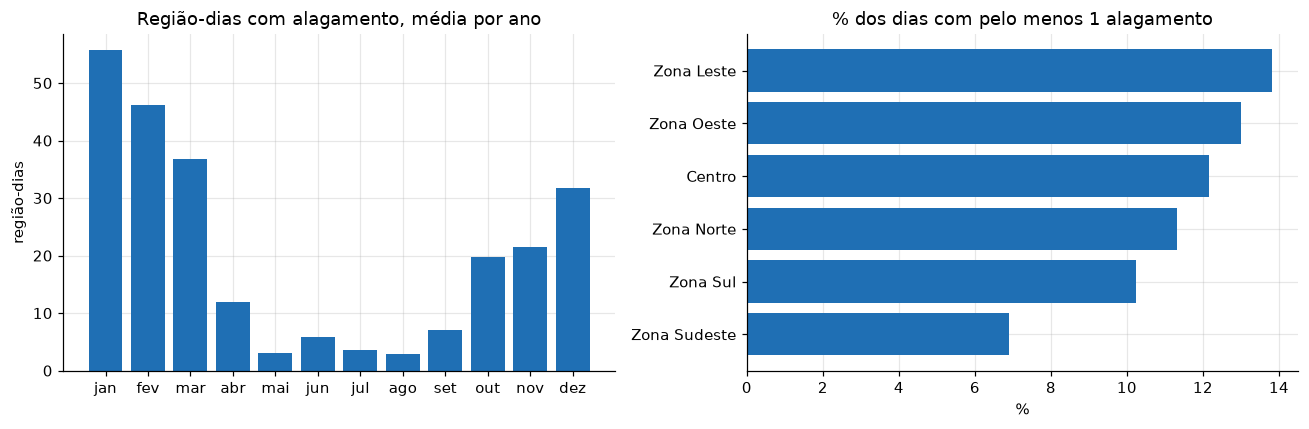

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

por_mes = tabela.groupby("mes")["alagou"].sum() / tabela["ano"].nunique()
ax[0].bar(por_mes.index, por_mes.values, color=AZUL)
ax[0].set_xticks(range(1, 13), ["jan", "fev", "mar", "abr", "mai", "jun",
                                "jul", "ago", "set", "out", "nov", "dez"])
ax[0].set_title("Região-dias com alagamento, média por ano")
ax[0].set_ylabel("região-dias")

por_regiao = tabela.groupby("regiao")["alagou"].mean().sort_values() * 100
ax[1].barh(por_regiao.index, por_regiao.values, color=AZUL)
ax[1].set_title("% dos dias com pelo menos 1 alagamento")
ax[1].set_xlabel("%")

plt.tight_layout()
plt.savefig(PASTA_FIG / "01_quando_e_onde.png", bbox_inches="tight")
plt.show()

Dá para ver duas coisas logo de cara.

A primeira é a **época do ano**. Janeiro tem em média uns 56 região-dias com alagamento por ano, e de maio a agosto quase não há registro. É o período chuvoso de novembro a março, o mesmo em que a Prefeitura e o CGE fazem o Plano Preventivo Chuvas de Verão. Por isso o mês entra como variável.

A segunda é que **as regiões não são iguais**. A Zona Leste teve alagamento em 13,8% dos dias, e a Zona Sudeste em 6,9%, metade disso.

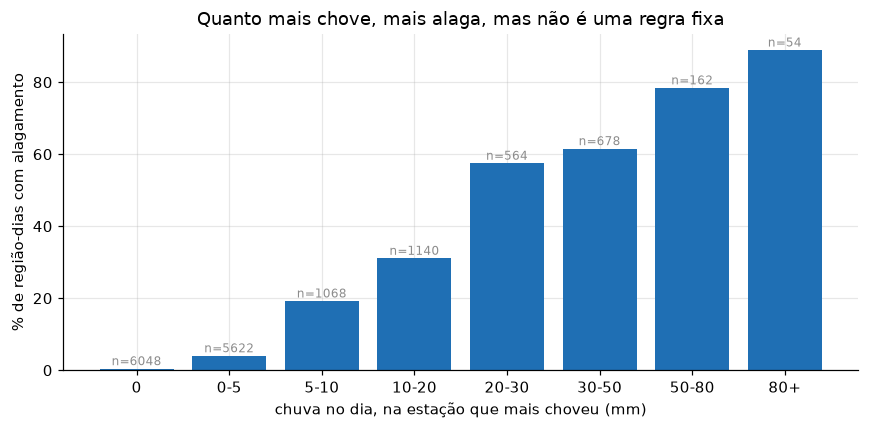

,mean,size
faixa_chuva,,
0,0.004,6048
0-5,0.040,5622
5-10,0.192,1068
10-20,0.311,1140
20-30,0.574,564
30-50,0.615,678
50-80,0.784,162
80+,0.889,54


In [12]:
faixas = [-0.1, 0, 5, 10, 20, 30, 50, 80, 300]
rotulos = ["0", "0-5", "5-10", "10-20", "20-30", "30-50", "50-80", "80+"]
tabela["faixa_chuva"] = pd.cut(tabela["chuva_maior_estacao"], faixas, labels=rotulos)

chance = tabela.groupby("faixa_chuva", observed=True)["alagou"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(chance.index.astype(str), chance["mean"] * 100, color=AZUL)
for i, (p, n) in enumerate(zip(chance["mean"], chance["size"])):
    ax.text(i, p * 100 + 1, f"n={n}", ha="center", fontsize=8, color=CINZA)
ax.set_xlabel("chuva no dia, na estação que mais choveu (mm)")
ax.set_ylabel("% de região-dias com alagamento")
ax.set_title("Quanto mais chove, mais alaga, mas não é uma regra fixa")
plt.tight_layout()
plt.savefig(PASTA_FIG / "02_chuva_vs_alagamento.png", bbox_inches="tight")
plt.show()

tabela = tabela.drop(columns="faixa_chuva")
chance

Quando nenhuma das estações registra chuva, quase não alaga (0,4% das região-dias). Com 20 a 30 mm, alaga em 57% dos casos, e acima de 80 mm em 89%. A relação é forte, mas não é uma régua. Entre 5 e 20 mm, a chance fica entre 19% e 31%, e é nessa faixa do meio que um modelo pode ajudar mais do que uma regra fixa.

O 0,4% com chuva zero também conta uma história: houve alagamento em dias em que nenhuma das duas estações marcou chuva. Ou seja, choveu forte em outro ponto da cidade, longe dos pluviômetros.

## 3. Divisão treino/teste

A divisão é **por tempo**: treino de 2019 a 2023 e teste em 2024 e 2025.

Não sorteamos as linhas porque dias vizinhos são muito parecidos (um temporal costuma durar dois ou três dias, e as 6 regiões de um mesmo dia compartilham a mesma chuva). Num sorteio, o modelo veria no treino a quinta-feira e seria testado na sexta do mesmo temporal, e a nota ficaria melhor do que a realidade. Separar por ano também imita o uso real: aprender com o passado para prever o que ainda não aconteceu.

As 6 regiões viram colunas 0/1 (one-hot). A coluna `ano` fica de fora das variáveis. Ela só serve para dividir os dados e montar a validação cruzada.

In [13]:
VARIAVEIS = [c for c in tabela.columns if c not in ("data", "regiao", "n_pontos", "alagou", "ano")]

X = pd.get_dummies(tabela[VARIAVEIS + ["regiao"]], columns=["regiao"], prefix="reg", dtype=int)
y = tabela["alagou"]

ANO_CORTE = 2023
eh_treino = tabela["ano"] <= ANO_CORTE
X_treino, X_teste = X[eh_treino], X[~eh_treino]
y_treino, y_teste = y[eh_treino], y[~eh_treino]
anos_treino = tabela.loc[eh_treino, "ano"]

resumo = pd.DataFrame({
    "linhas": [len(y_treino), len(y_teste)],
    "com alagamento": [y_treino.sum(), y_teste.sum()],
    "% positivos": [y_treino.mean() * 100, y_teste.mean() * 100],
}, index=[f"treino (até {ANO_CORTE})", f"teste (depois de {ANO_CORTE})"])
print(X.shape[1], "variáveis:", list(X.columns))
resumo

20 variáveis: ['chuva_dia_A701', 'chuva_max_1h_A701', 'chuva_max_3h_A701', 'temp_max_A701', 'umidade_media_A701', 'chuva_dia_A771', 'chuva_max_1h_A771', 'chuva_max_3h_A771', 'temp_max_A771', 'chuva_maior_estacao', 'chuva_ontem', 'chuva_3d_antes', 'chuva_7d_antes', 'mes', 'reg_Centro', 'reg_Zona Leste', 'reg_Zona Norte', 'reg_Zona Oeste', 'reg_Zona Sudeste', 'reg_Zona Sul']


,linhas,com alagamento,% positivos
treino (até 2023),10956,1301,11.875
teste (depois de 2023),4380,422,9.635


## 4. Modelo

### Por que XGBoost

Dos modelos da lista (XGBoost, Random Forest, MLP, LSTM, KMeans + PCA), escolhemos o **XGBoost** (árvores de decisão em *gradient boosting*):

- Os dados são uma tabela com umas 20 colunas numéricas. Para esse formato, modelos de árvore costumam ser o ponto de partida mais forte.
- A relação entre chuva e alagamento não é linear. 10 mm espalhados no dia não fazem nada, enquanto 40 mm em uma hora param a Marginal. A árvore aprende esses "pontos de virada" sozinha, sem a gente precisar transformar as variáveis.
- Ele aceita valor faltando (NaN). Quando uma estação fica sem medir, o modelo usa a outra, e não precisamos inventar dado.
- Os parâmetros `learning_rate` e `n_estimators` permitem controlar bem o overfitting.

Os outros também foram considerados. KMeans + PCA é não supervisionado, e aqui temos o rótulo (alagou ou não), então não faz sentido jogar fora essa informação. LSTM é para sequências longas e pediria bem mais dado do que ~2.500 dias. MLP precisaria normalizar tudo e, em tabela pequena, costuma perder para árvore. O Random Forest seria a alternativa mais próxima. Ficamos com o XGBoost porque cada árvore nova corrige os erros das anteriores, o que ajuda quando a classe positiva é rara como aqui.

### Métrica

Só uma parte pequena das linhas tem alagamento. Um modelo que dissesse "não alaga" sempre teria acurácia alta e seria inútil, então a acurácia não serve. A métrica principal é a **precisão média (average precision, área sob a curva precisão × recall)**, que só sobe se o modelo acertar os dias que alagam. Também mostramos ROC-AUC, precisão, recall e F1.

### Uma régua para comparar

Para saber se o modelo vale a pena, comparamos com a regra que qualquer pessoa usaria: *"se choveu mais de X mm, alerta"*. O X é escolhido no treino (o que dá o maior F1).

In [14]:
limites = np.arange(1, 81)
f1_por_limite = [f1_score(y_treino, (X_treino["chuva_maior_estacao"] >= L).astype(int)) for L in limites]
LIMITE_REGRA = int(limites[int(np.argmax(f1_por_limite))])
print(f"regra simples: alerta se alguma estação marcar {LIMITE_REGRA} mm ou mais no dia")

regra simples: alerta se alguma estação marcar 12 mm ou mais no dia


### 4.1 Busca de hiperparâmetros

Variamos **3 hiperparâmetros**, num total de **4 × 3 × 3 = 36 combinações**:

| Hiperparâmetro | O que controla | Valores testados |
|---|---|---|
| `max_depth` | profundidade de cada árvore (quanto ela "decora" detalhes) | 2, 3, 5, 8 |
| `learning_rate` | quanto cada árvore nova corrige da anterior | 0.03, 0.1, 0.3 |
| `n_estimators` | quantidade de árvores | 100, 300, 600 |

Os outros parâmetros ficaram no padrão da biblioteca.

A **validação cruzada roda só no treino** e é feita **por ano** (`GroupKFold` com o ano como grupo). Em cada rodada, o modelo treina com 4 anos e é validado no ano que ficou de fora. São 5 rodadas, uma por ano de 2019 a 2023. Assim, a validação também nunca mistura dias do mesmo temporal entre treino e validação. O conjunto de teste (2024-2025) não entra em nada aqui.

Não usamos peso para compensar a classe rara (`scale_pos_weight`). O peso distorce a probabilidade que sai do modelo, e queremos que "40% de risco" signifique algo perto de 40%. O desequilíbrio é tratado depois, na escolha do limiar de alerta.

In [15]:
N_DOBRAS = anos_treino.nunique()

modelo = XGBClassifier(tree_method="hist", eval_metric="logloss",
                       random_state=SEMENTE, n_jobs=4)

grade_params = {
    "max_depth": [2, 3, 5, 8],
    "learning_rate": [0.03, 0.1, 0.3],
    "n_estimators": [100, 300, 600],
}

busca = GridSearchCV(modelo, grade_params, scoring="average_precision",
                     cv=GroupKFold(n_splits=N_DOBRAS), return_train_score=True,
                     n_jobs=1, refit=True)
busca.fit(X_treino, y_treino, groups=anos_treino)

res = pd.DataFrame(busca.cv_results_)
res = res.rename(columns={"param_max_depth": "max_depth", "param_learning_rate": "learning_rate",
                          "param_n_estimators": "n_estimators", "mean_train_score": "AP_treino",
                          "mean_test_score": "AP_validacao", "std_test_score": "desvio_validacao"})
res = res.astype({"max_depth": int, "n_estimators": int, "learning_rate": float})
res["diferenca"] = res["AP_treino"] - res["AP_validacao"]
tabela_busca = (res[["max_depth", "learning_rate", "n_estimators", "AP_treino",
                     "AP_validacao", "desvio_validacao", "diferenca"]]
                .sort_values("AP_validacao", ascending=False).reset_index(drop=True))
tabela_busca.index += 1
tabela_busca.to_csv(PASTA_FIG / "busca_hiperparametros.csv", index_label="posicao")
print("melhor combinação:", busca.best_params_)
tabela_busca

melhor combinação: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 300}


,max_depth,learning_rate,n_estimators,AP_treino,AP_validacao,desvio_validacao,diferenca
1,2,0.03,300,0.728,0.656,0.063,0.072
2,3,0.03,300,0.774,0.656,0.062,0.118
3,2,0.10,100,0.734,0.655,0.063,0.079
4,2,0.03,600,0.761,0.655,0.061,0.107
5,5,0.03,100,0.805,0.653,0.059,0.152
6,5,0.03,300,0.873,0.652,0.061,0.221
7,5,0.10,100,0.884,0.652,0.058,0.232
8,3,0.10,100,0.783,0.651,0.060,0.132
9,3,0.03,600,0.822,0.650,0.056,0.173
10,2,0.10,300,0.794,0.650,0.057,0.144


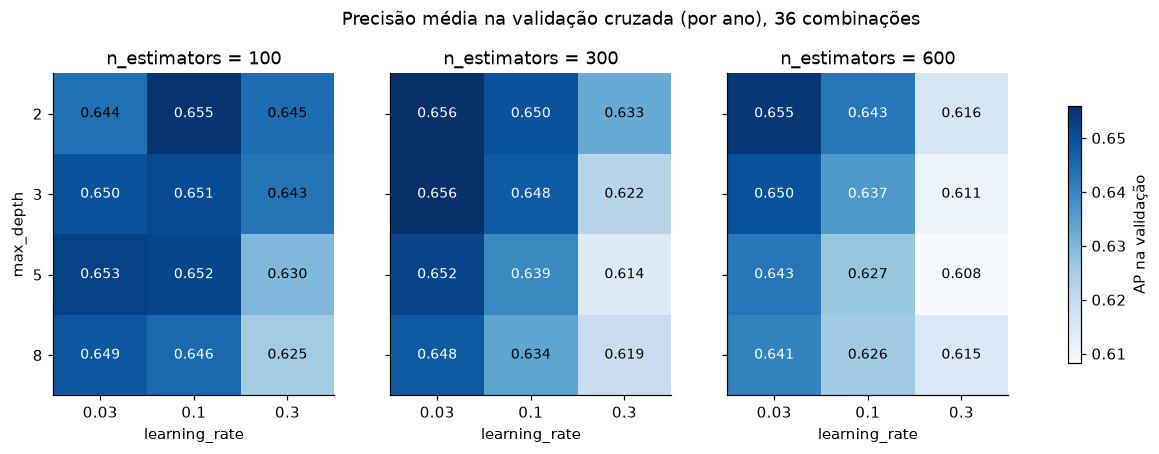

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, n in zip(axes, grade_params["n_estimators"]):
    pivo = (res[res["n_estimators"] == n]
            .pivot(index="max_depth", columns="learning_rate", values="AP_validacao"))
    im = ax.imshow(pivo.values, cmap="Blues", vmin=res["AP_validacao"].min(),
                   vmax=res["AP_validacao"].max(), aspect="auto")
    ax.set_xticks(range(len(pivo.columns)), pivo.columns)
    ax.set_yticks(range(len(pivo.index)), pivo.index)
    ax.set_xlabel("learning_rate")
    ax.set_title(f"n_estimators = {n}")
    ax.grid(False)
    for i in range(pivo.shape[0]):
        for j in range(pivo.shape[1]):
            v = pivo.values[i, j]
            ax.text(j, i, f"{v:.3f}", ha="center", va="center",
                    color="white" if v > pivo.values.mean() else "black", fontsize=9)
axes[0].set_ylabel("max_depth")
fig.colorbar(im, ax=axes, shrink=0.8, label="AP na validação")
fig.suptitle("Precisão média na validação cruzada (por ano), 36 combinações", y=1.03)
plt.savefig(PASTA_FIG / "03_busca_hiperparametros.png", bbox_inches="tight")
plt.show()

Três padrões aparecem na busca:

- `learning_rate = 0.3` vai mal em quase todas as combinações. O modelo aprende rápido demais e decora o treino. Das 12 piores combinações, 9 usam esse valor.
- Árvores rasas (`max_depth` 2 ou 3) com `learning_rate` 0.03 ou 0.1 ficam no topo. O problema não pede interações complicadas, e o que manda é quanto e com que força choveu.
- A diferença entre as primeiras colocadas é muito pequena. Da 1ª à 10ª, a AP de validação vai de 0,656 a 0,650, bem menos que o desvio entre um ano e outro (cerca de 0,06). Na prática, várias combinações simples empatam. A escolhida (`max_depth=2`, `learning_rate=0.03`, `n_estimators=300`) está entre as mais simples e tem uma das menores diferenças entre treino e validação (0,07).

O gráfico abaixo mostra a mesma busca de outro jeito. As combinações estão ordenadas da mais simples para a mais complexa, com a nota no treino e na validação lado a lado. A ordem é aproximada, pelo produto `max_depth × n_estimators × learning_rate`, que dá uma noção de quanto o modelo consegue "decorar". A distância entre as duas linhas é o overfitting.

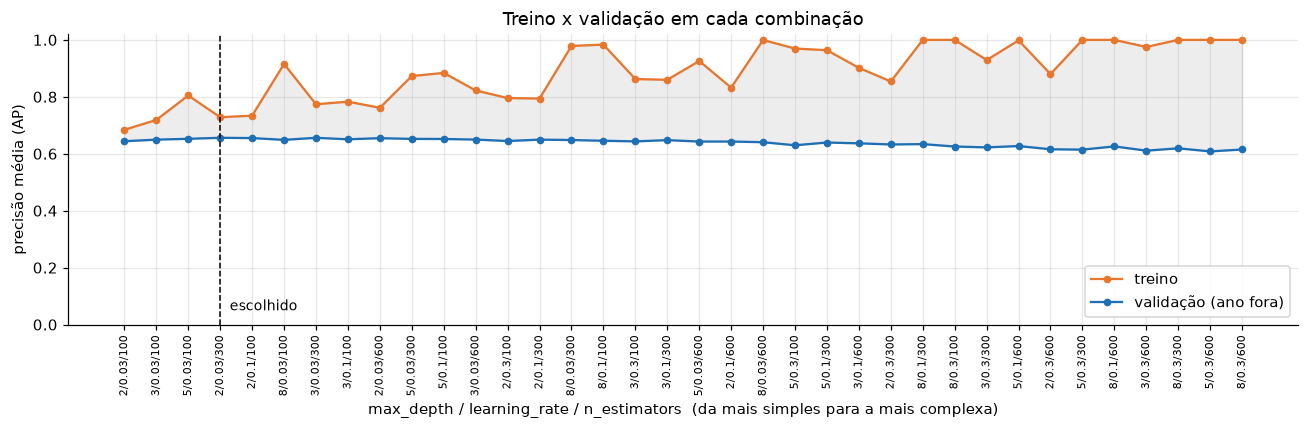

In [17]:
res["complexidade"] = res["max_depth"] * res["n_estimators"] * res["learning_rate"]
ordem = res.sort_values("complexidade").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(ordem.index, ordem["AP_treino"], "o-", color=LARANJA, label="treino", ms=4)
ax.plot(ordem.index, ordem["AP_validacao"], "o-", color=AZUL, label="validação (ano fora)", ms=4)
ax.fill_between(ordem.index, ordem["AP_validacao"], ordem["AP_treino"], color=CINZA, alpha=0.15)
melhor = ordem.index[ordem["rank_test_score"] == 1][0]
ax.axvline(melhor, color="black", ls="--", lw=1)
ax.text(melhor + 0.3, 0.05, "escolhido", fontsize=9)
ax.set_xticks(ordem.index, [f"{d}/{lr}/{n}" for d, lr, n in
                            zip(ordem["max_depth"], ordem["learning_rate"], ordem["n_estimators"])],
              rotation=90, fontsize=7)
ax.set_xlabel("max_depth / learning_rate / n_estimators  (da mais simples para a mais complexa)")
ax.set_ylabel("precisão média (AP)")
ax.set_ylim(0, 1.02)
ax.legend()
ax.set_title("Treino x validação em cada combinação")
plt.tight_layout()
plt.savefig(PASTA_FIG / "04_overfitting_busca.png", bbox_inches="tight")
plt.show()

O overfitting fica bem visível. Conforme o modelo fica mais complexo, a nota no treino sobe até 1,0, ou seja, ele acerta todos os dias que já viu. A validação não acompanha e até cai um pouco, de ~0,65 para ~0,61. Nas combinações mais complexas, a diferença entre treino e validação chega perto de 0,4. Esses modelos decoraram as particularidades dos anos de treino (aquele temporal específico, naquele dia específico) em vez de aprender a relação entre chuva e alagamento. A combinação escolhida fica no começo do gráfico, onde as duas linhas estão mais próximas.

### 4.2 Limiar de alerta

O modelo devolve uma probabilidade, mas o app precisa decidir quando avisar. O limiar padrão de 0,5 não é bom quando a classe positiva é rara. Para escolher o limiar sem usar o teste, pegamos as previsões **fora da dobra** da validação cruzada (cada ano é previsto por um modelo que não o viu) e escolhemos o limiar que maximiza o F1, o equilíbrio entre não deixar alagamento passar (recall) e não dar alarme falso (precisão).

Alarme falso demais também é um problema real: se o celular apita toda vez que garoa, o morador desativa a notificação e não recebe o aviso no dia que importa.

limiar escolhido: 0.290


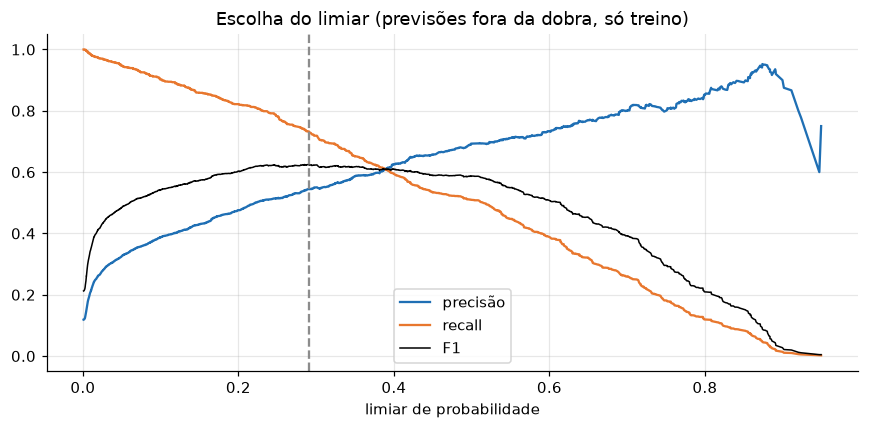

In [18]:
melhor_modelo = busca.best_estimator_

prob_oof = cross_val_predict(XGBClassifier(**melhor_modelo.get_params()), X_treino, y_treino,
                             cv=GroupKFold(n_splits=N_DOBRAS), groups=anos_treino,
                             method="predict_proba")[:, 1]

prec, rec, lim = precision_recall_curve(y_treino, prob_oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
LIMIAR = float(lim[np.argmax(f1s)])
print(f"limiar escolhido: {LIMIAR:.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lim, prec[:-1], color=AZUL, label="precisão")
ax.plot(lim, rec[:-1], color=LARANJA, label="recall")
ax.plot(lim, f1s, color="black", lw=1, label="F1")
ax.axvline(LIMIAR, color=CINZA, ls="--")
ax.set_xlabel("limiar de probabilidade")
ax.set_title("Escolha do limiar (previsões fora da dobra, só treino)")
ax.legend()
plt.tight_layout()
plt.savefig(PASTA_FIG / "05_limiar.png", bbox_inches="tight")
plt.show()

## 5. Resultados em treino e teste

O modelo final é o da melhor combinação, treinado de novo com todos os anos de treino (o `refit` do `GridSearchCV`). Abaixo, as métricas lado a lado em três situações:

- **treino**: o modelo avaliado nos mesmos dados em que aprendeu
- **validação cruzada**: cada ano de treino previsto por um modelo que não o viu
- **teste**: 2024 e 2025, que o modelo nunca viu e que não foram usados em nenhuma escolha

In [19]:
def metricas(y_real, prob, limiar):
    prev = (prob >= limiar).astype(int)
    return {
        "AP (prec. média)": average_precision_score(y_real, prob),
        "ROC-AUC": roc_auc_score(y_real, prob),
        "precisão": precision_score(y_real, prev, zero_division=0),
        "recall": recall_score(y_real, prev),
        "F1": f1_score(y_real, prev),
    }


prob_treino = melhor_modelo.predict_proba(X_treino)[:, 1]
prob_teste = melhor_modelo.predict_proba(X_teste)[:, 1]

comparacao = pd.DataFrame({
    "treino": metricas(y_treino, prob_treino, LIMIAR),
    "validação cruzada": metricas(y_treino, prob_oof, LIMIAR),
    "teste (2024-2025)": metricas(y_teste, prob_teste, LIMIAR),
})

# na regra o "score" e a propria chuva
chuva_teste = X_teste["chuva_maior_estacao"].fillna(0)
comparacao["regra simples (teste)"] = metricas(y_teste, chuva_teste, LIMITE_REGRA)
comparacao.round(3)

,treino,validação cruzada,teste (2024-2025),regra simples (teste)
AP (prec. média),0.720,0.652,0.638,0.584
ROC-AUC,0.945,0.927,0.946,0.938
precisão,0.579,0.545,0.539,0.490
recall,0.772,0.733,0.775,0.794
F1,0.662,0.625,0.636,0.606


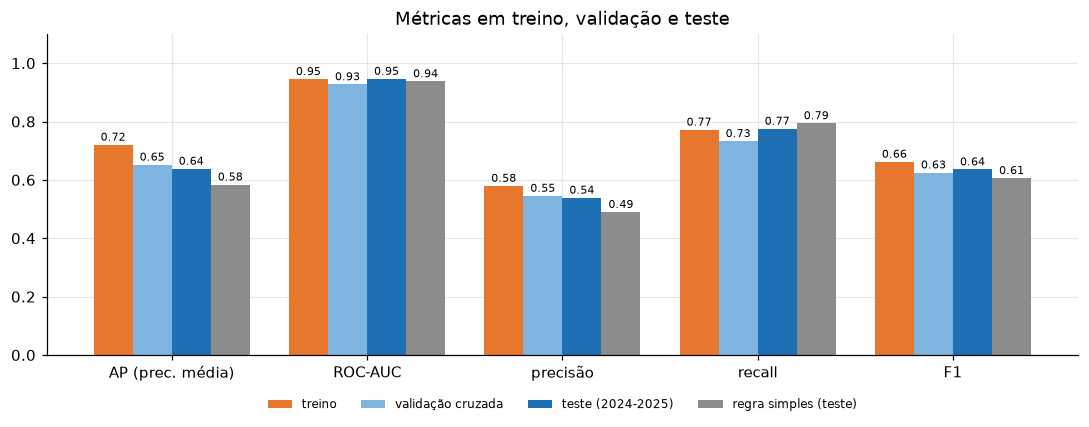

In [20]:
fig, ax = plt.subplots(figsize=(10, 4))
cols = ["treino", "validação cruzada", "teste (2024-2025)", "regra simples (teste)"]
cores = [LARANJA, "#7fb3e0", AZUL, CINZA]
largura = 0.2
x = np.arange(len(comparacao.index))
for i, (c, cor) in enumerate(zip(cols, cores)):
    barras = ax.bar(x + (i - 1.5) * largura, comparacao[c], largura, label=c, color=cor)
    ax.bar_label(barras, fmt="%.2f", fontsize=7, padding=1)
ax.set_xticks(x, comparacao.index)
ax.set_ylim(0, 1.1)
ax.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
ax.set_title("Métricas em treino, validação e teste")
plt.tight_layout()
plt.savefig(PASTA_FIG / "06_treino_x_teste.png", bbox_inches="tight")
plt.show()

Em números absolutos, no período de teste:

In [21]:
def contagem(y_real, alerta):
    tn, fp, fn, tp = confusion_matrix(y_real, alerta).ravel()
    return {"alagamentos avisados": tp, "alagamentos sem aviso": fn,
            "alarmes falsos": fp, "total de alertas": tp + fp}


pd.DataFrame({
    "modelo": contagem(y_teste, (prob_teste >= LIMIAR).astype(int)),
    f"regra (>= {LIMITE_REGRA} mm)": contagem(y_teste, (chuva_teste >= LIMITE_REGRA).astype(int)),
})

,modelo,regra (>= 12 mm)
alagamentos avisados,327,335
alagamentos sem aviso,95,87
alarmes falsos,280,349
total de alertas,607,684


O que a tabela e os gráficos mostram:

- **O overfitting do modelo final é pequeno.** A AP vai de 0,72 no treino para 0,65 na validação e 0,64 no teste, e o ROC-AUC fica praticamente igual nos três (0,93 a 0,95). Um treino um pouco melhor que o teste é normal. Problema seria uma diferença como a dos modelos profundos da busca, com 1,0 no treino e 0,6 na validação.
- **A validação cruzada previu bem o teste.** A nota da validação por ano (0,65) ficou muito perto da do teste (0,64), sinal de que a validação foi honesta e de que o desempenho em anos que o modelo nunca viu é estável.
- **A AP do teste é um pouco menor também porque 2024-2025 tiveram menos alagamentos** (9,6% das linhas, contra 11,9% no treino). A AP depende da proporção de positivos: um modelo que chutasse teria AP de 0,096. O nosso fica em 0,64, cerca de 6,6 vezes isso.
- **Contra a regra simples, o modelo ganha nas métricas que não dependem de limiar** (AP 0,64 contra 0,58). No limiar escolhido, ele avisa quase os mesmos alagamentos (327 contra 335) com 69 alarmes falsos a menos (280 contra 349, uns 20% a menos). O ganho não está em avisar mais, e sim em avisar melhor: um alerta do modelo se confirma em 54% das vezes, contra 49% na regra.

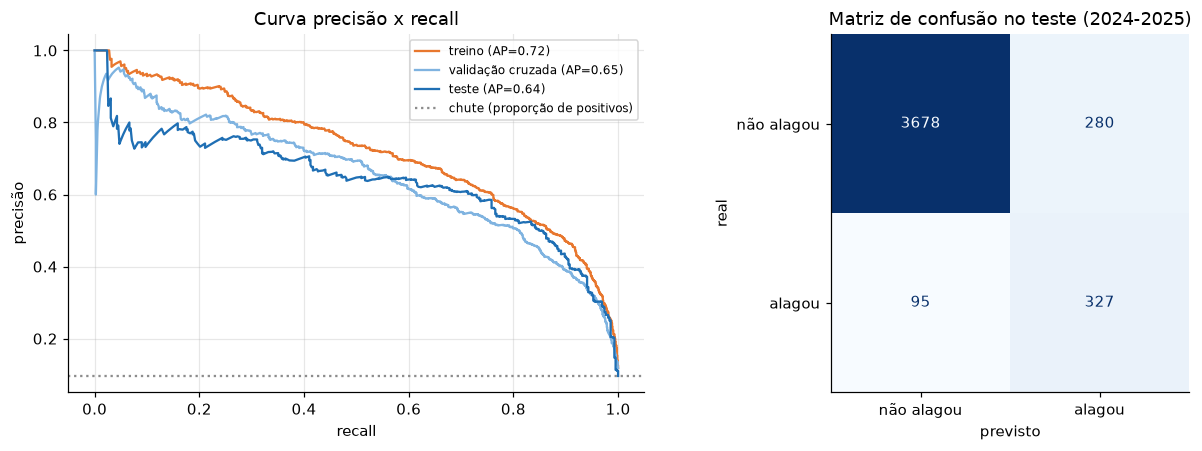

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))

for nome, yr, p, cor in [("treino", y_treino, prob_treino, LARANJA),
                          ("validação cruzada", y_treino, prob_oof, "#7fb3e0"),
                          ("teste", y_teste, prob_teste, AZUL)]:
    pr, rc, _ = precision_recall_curve(yr, p)
    ax[0].plot(rc, pr, color=cor, label=f"{nome} (AP={average_precision_score(yr, p):.2f})")
ax[0].axhline(y_teste.mean(), color=CINZA, ls=":", label="chute (proporção de positivos)")
ax[0].set_xlabel("recall")
ax[0].set_ylabel("precisão")
ax[0].set_title("Curva precisão x recall")
ax[0].legend(fontsize=8)

ConfusionMatrixDisplay(confusion_matrix(y_teste, (prob_teste >= LIMIAR).astype(int)),
                       display_labels=["não alagou", "alagou"]).plot(ax=ax[1], cmap="Blues",
                                                                     colorbar=False)
ax[1].set_title("Matriz de confusão no teste (2024-2025)")
ax[1].set_xlabel("previsto")
ax[1].set_ylabel("real")
ax[1].grid(False)
plt.tight_layout()
plt.savefig(PASTA_FIG / "07_curva_pr_matriz.png", bbox_inches="tight")
plt.show()

### 5.1 Por região

O app avisa por região, então também vale olhar como o modelo vai em cada uma no período de teste.

In [23]:
teste = tabela.loc[~eh_treino, ["data", "regiao", "n_pontos", "alagou"]].copy()
teste["prob"] = prob_teste
teste["alerta"] = (teste["prob"] >= LIMIAR).astype(int)

por_regiao_teste = teste.groupby("regiao").apply(lambda d: pd.Series({
    "dias que alagou": d["alagou"].sum(),
    "alertas dados": d["alerta"].sum(),
    "alagamentos avisados (recall)": recall_score(d["alagou"], d["alerta"], zero_division=0),
    "alertas que se confirmaram (precisão)": precision_score(d["alagou"], d["alerta"], zero_division=0),
}), include_groups=False)
por_regiao_teste = por_regiao_teste.astype({"dias que alagou": int, "alertas dados": int})
por_regiao_teste

,dias que alagou,alertas dados,alagamentos avisados (recall),alertas que se confirmaram (precisão)
regiao,,,,
Centro,72,110,0.847,0.555
Zona Leste,100,107,0.730,0.682
Zona Norte,72,106,0.819,0.557
Zona Oeste,84,106,0.762,0.604
Zona Sudeste,46,73,0.674,0.425
Zona Sul,48,105,0.812,0.371


O recall vai de 67% (Zona Sudeste) a 85% (Centro). A precisão varia mais: na Zona Leste, 68% dos alertas se confirmam, e na Zona Sul só 37%. A explicação está nas variáveis. O modelo só conhece a chuva de dois pontos da cidade, então, quando chove forte em Interlagos, ele tende a avisar várias regiões de uma vez. A Zona Sul, que alagou em 48 dias do teste, recebeu quase tantos alertas quanto a Zona Leste, que alagou em 100 (105 contra 107).

Resumindo, o modelo sabe bem **quando** a cidade vai alagar, mas sabe pouco **onde**.

### 5.2 O que o modelo aprendeu

Importância por permutação no conjunto de teste: embaralhamos uma variável de cada vez e medimos quanto a precisão média cai. Se a nota cai muito, o modelo depende daquela variável.

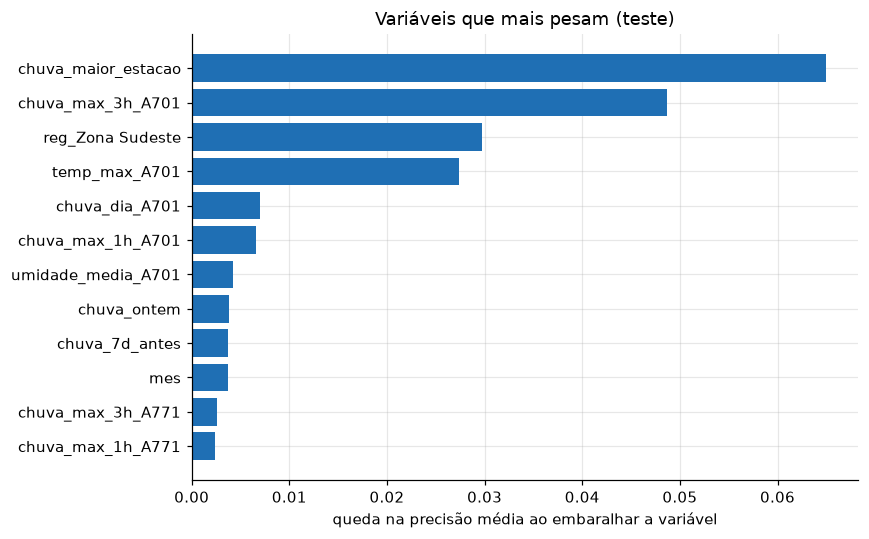

In [24]:
imp = permutation_importance(melhor_modelo, X_teste, y_teste, scoring="average_precision",
                             n_repeats=10, random_state=SEMENTE, n_jobs=1)
importancia = (pd.Series(imp.importances_mean, index=X_teste.columns)
               .sort_values(ascending=True).tail(12))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importancia.index, importancia.values, color=AZUL)
ax.set_xlabel("queda na precisão média ao embaralhar a variável")
ax.set_title("Variáveis que mais pesam (teste)")
plt.tight_layout()
plt.savefig(PASTA_FIG / "08_importancia.png", bbox_inches="tight")
plt.show()

As variáveis que mais pesam fazem sentido físico:

1. `chuva_maior_estacao`: quanto choveu onde mais choveu.
2. `chuva_max_3h_A701`: a intensidade. Muita chuva em pouco tempo é o que a galeria pluvial não consegue escoar.
3. `reg_Zona Sudeste`: a única região que o modelo trata de um jeito diferente, porque ela alaga bem menos que as outras.
4. `temp_max_A701`: dia muito quente favorece a pancada forte no fim da tarde, o padrão típico do verão em São Paulo.

A chuva dos dias anteriores (`chuva_ontem`, `chuva_7d_antes`) pesa pouco. Aqui, quem causa o alagamento é a chuva intensa do próprio dia, mais do que o solo já encharcado.

### 5.3 Um dia de teste, olhando de perto

Pegamos o dia do período de teste com mais pontos de alagamento registrados pelo CGE e comparamos com o que o modelo teria dito para cada região.

In [25]:
dia_pior = teste.groupby("data")["n_pontos"].sum().idxmax()
exemplo = teste[teste["data"] == dia_pior][["regiao", "n_pontos", "prob", "alerta"]]
clima_dia = clima.loc[dia_pior, ["chuva_dia_A701", "chuva_dia_A771", "chuva_max_1h_A701",
                                 "chuva_max_1h_A771", "chuva_3d_antes"]]
print(f"{dia_pior:%d/%m/%Y}: {exemplo['n_pontos'].sum()} pontos de alagamento no CGE")
print(clima_dia.round(1).to_string())
exemplo.sort_values("prob", ascending=False)

25/12/2024: 46 pontos de alagamento no CGE
chuva_dia_A701        3.4
chuva_dia_A771       44.0
chuva_max_1h_A701     2.8
chuva_max_1h_A771    27.4
chuva_3d_antes        7.4


,regiao,n_pontos,prob,alerta
13111,Zona Leste,12,0.488,1
13110,Centro,5,0.473,1
13112,Zona Norte,0,0.473,1
13113,Zona Oeste,16,0.473,1
13115,Zona Sul,5,0.473,1
13114,Zona Sudeste,8,0.387,1


No Natal de 2024, o CGE registrou 46 pontos de alagamento. A chuva foi bem concentrada: Interlagos marcou 44 mm (27,4 mm em uma única hora) e o Mirante, na zona norte, só 3,4 mm. O modelo deu entre 39% e 49% de risco para todas as regiões, todas ficaram em nível de atenção e o aviso teria saído. Mas a Zona Norte recebeu o mesmo risco das outras (47%) e não teve nenhum alagamento. É o limite que já apareceu na análise por região: com duas estações, o modelo não consegue separar quem vai ser atingido.

### 5.4 Os alagamentos que passaram sem aviso

Vale olhar os erros que mais importam para o morador, os dias em que alagou e o modelo ficou em "normal". Quanto choveu nas estações nesses dias?

In [26]:
perdidos = teste[(teste["alagou"] == 1) & (teste["alerta"] == 0)].merge(
    clima[["chuva_maior_estacao"]], left_on="data", right_index=True)

print(f"{len(perdidos)} região-dias alagaram sem aviso no teste")
print(f"  em {(perdidos['chuva_maior_estacao'] < 5).sum()} deles, nenhuma das duas estações passou de 5 mm no dia")
print(f"  em {(perdidos['chuva_maior_estacao'] < 10).sum()} deles, nenhuma passou de 10 mm")
print(f"  mediana de chuva na estação mais molhada: {perdidos['chuva_maior_estacao'].median():.1f} mm")

95 região-dias alagaram sem aviso no teste
  em 42 deles, nenhuma das duas estações passou de 5 mm no dia
  em 61 deles, nenhuma passou de 10 mm
  mediana de chuva na estação mais molhada: 5.8 mm


Dos 95 alagamentos que passaram sem aviso, 42 aconteceram em dias em que nenhuma das duas estações passou de 5 mm, e 61 com menos de 10 mm. Nesses casos o modelo não errou a conta: a chuva que causou o alagamento simplesmente não passou pelo Mirante nem por Interlagos. Com dois pluviômetros para uma cidade de 1.500 km², isso vai acontecer, e nenhum ajuste de hiperparâmetro resolve. Só mais pontos de medição resolvem.

## 6. O que isso significa para o morador

Para o app, a probabilidade vira três níveis de aviso por região:

- **normal**: abaixo do limiar escolhido
- **atenção**: entre o limiar e 50%
- **alerta**: 50% ou mais, quando o modelo acha mais provável alagar do que não

A tabela mostra, no período de teste, quantas vezes cada nível apareceu e quantas dessas vezes a região alagou de fato.

In [27]:
cortes = [0, LIMIAR, 0.5, 1] if LIMIAR < 0.5 else [0, LIMIAR, 1]
nomes = ["normal", "atenção", "alerta"][:len(cortes) - 1]
teste["nivel"] = pd.cut(teste["prob"], cortes, labels=nomes, include_lowest=True)

leitura = teste.groupby("nivel", observed=True).agg(regiao_dias=("alagou", "size"),
                                                     alagou_de_fato=("alagou", "sum"))
leitura["% em que alagou"] = leitura["alagou_de_fato"] / leitura["regiao_dias"] * 100
leitura["% de todos os alagamentos"] = leitura["alagou_de_fato"] / teste["alagou"].sum() * 100
leitura.round(1)

,regiao_dias,alagou_de_fato,% em que alagou,% de todos os alagamentos
nivel,,,,
normal,3773,95,2.5,22.5
atenção,243,91,37.4,21.6
alerta,364,236,64.8,55.9


Traduzindo para quem mora perto de uma rua que alaga:

- Quando o app mostrar **alerta**, a região alagou de verdade em 65% das vezes no período de teste. Esse nível concentrou 56% de todos os alagamentos de 2024 e 2025.
- **Atenção** se confirmou em 37% das vezes e pegou outros 22% dos alagamentos. É o aviso para evitar a rua que costuma encher, deixar o carro num lugar mais alto e ficar de olho no app.
- No nível **normal**, só 2,5% das região-dias alagaram, então na grande maioria dos dias a pessoa pode sair tranquila. Somando atenção e alerta, o aviso apareceu em cerca de 14% dos dias de cada região, quase todos no verão. O app não fica apitando à toa, e isso conta: aviso que toca demais acaba desativado.

Os nomes "atenção" e "alerta" foram escolhidos de propósito, porque são os mesmos que o CGE usa nos comunicados à população.

**O que o modelo responde bem:** *se* vai alagar num dia de chuva, com menos alarme falso que a regra "choveu 12 mm ou mais" (20% a menos).

**O que ele não responde:** *onde*. Ele só enxerga dois pontos de chuva numa cidade inteira, e 42 dos alagamentos que passaram sem aviso foram em dias em que essas estações quase não registraram chuva.

É exatamente para isso que existem as outras partes do AlagaAlerta. O modelo dá o nível de risco da região, e os sensores ultrassônicos nos bueiros e córregos (o mesmo princípio que a rede telemétrica do SAISP, usada pelo CGE, aplica para medir o nível dos rios) e os relatos dos moradores mostram em qual rua a água está subindo.

**Limitações e próximos passos**

1. O modelo foi treinado com a chuva **medida** no dia. Para avisar com horas de antecedência, a entrada no app precisa ser a **previsão** de chuva (INMET ou CGE), e a qualidade do aviso passa a depender também da previsão.
2. Os pontos do CGE vêm da equipe do centro e de observadores da CET, das subprefeituras e da Defesa Civil, então a base pende para as vias grandes: 57% dos pontos são avenidas, 5% são as marginais e só 25% são ruas. Uma rua pequena de bairro que alaga toda chuva pode nem aparecer, e é aí que o relato do morador no app completa a informação.
3. Colocar no modelo os pluviômetros do CGE e do Cemaden, que cobrem muito mais pontos da cidade, para ele enxergar *onde* choveu.
4. Quando os sensores do AlagaAlerta tiverem histórico real de nível da água, usar essa medida como variável.

**ODS:** 11 (cidades sustentáveis, meta 11.5, reduzir o número de pessoas afetadas por desastres, inclusive os ligados à água) e 13 (ação contra a mudança do clima, meta 13.1, aumentar a capacidade de adaptação a eventos climáticos extremos).